<a href="https://colab.research.google.com/github/Pratster95/tpus-jax/blob/main/Jax_Workshop_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Demystifying the JAX Black Box: Hands-On Lab

Welcome to the **AI Builders Global Conference 2026** JAX Workshop!

This notebook is a **"Broken vs. Fixed"** guided lab. Each section shows a real JAX pitfall, the tool you use to diagnose it, and the fix. Look for:

* ❌ **Broken** cells: run them and watch what goes wrong
* 🔍 **Diagnose** cells: the debugging tool
* ✅ **Fixed** cells: the solution
* ✍️ **Your turn**: a short exercise. Solutions are hidden in 🔑 cells (double-click to reveal)

### Agenda
1. **The JAX Trinity**: `jit`, `vmap`, `grad`
2. **Tracing & Recompilation Storms**
3. **Shape & Batch-Size Mismatches**
4. **Memory: Rematerialization & Remat Policies**
5. **Profiling with Perfetto**

> **Runtime:** `Runtime → Change runtime type → TPU` (v5e) is ideal. GPU (T4) and CPU also work: problem sizes shrink automatically on CPU.

In [ ]:
# Setup and Imports
import warnings
warnings.filterwarnings("ignore", message=".*[Tt]ransparent hugepages.*")

import functools
import glob
import os
import time

import jax
import jax.numpy as jnp
import numpy as np

print(f"JAX version : {jax.__version__}")
print(f"Backend     : {jax.default_backend()}")
print(f"Devices     : {jax.devices()}")

---
## Part 0: What is JAX?

**JAX = NumPy + composable transformations + the XLA compiler.** You write ordinary array code; JAX transforms it (differentiate, batch, compile) and XLA turns it into fast code for CPU, GPU or TPU.

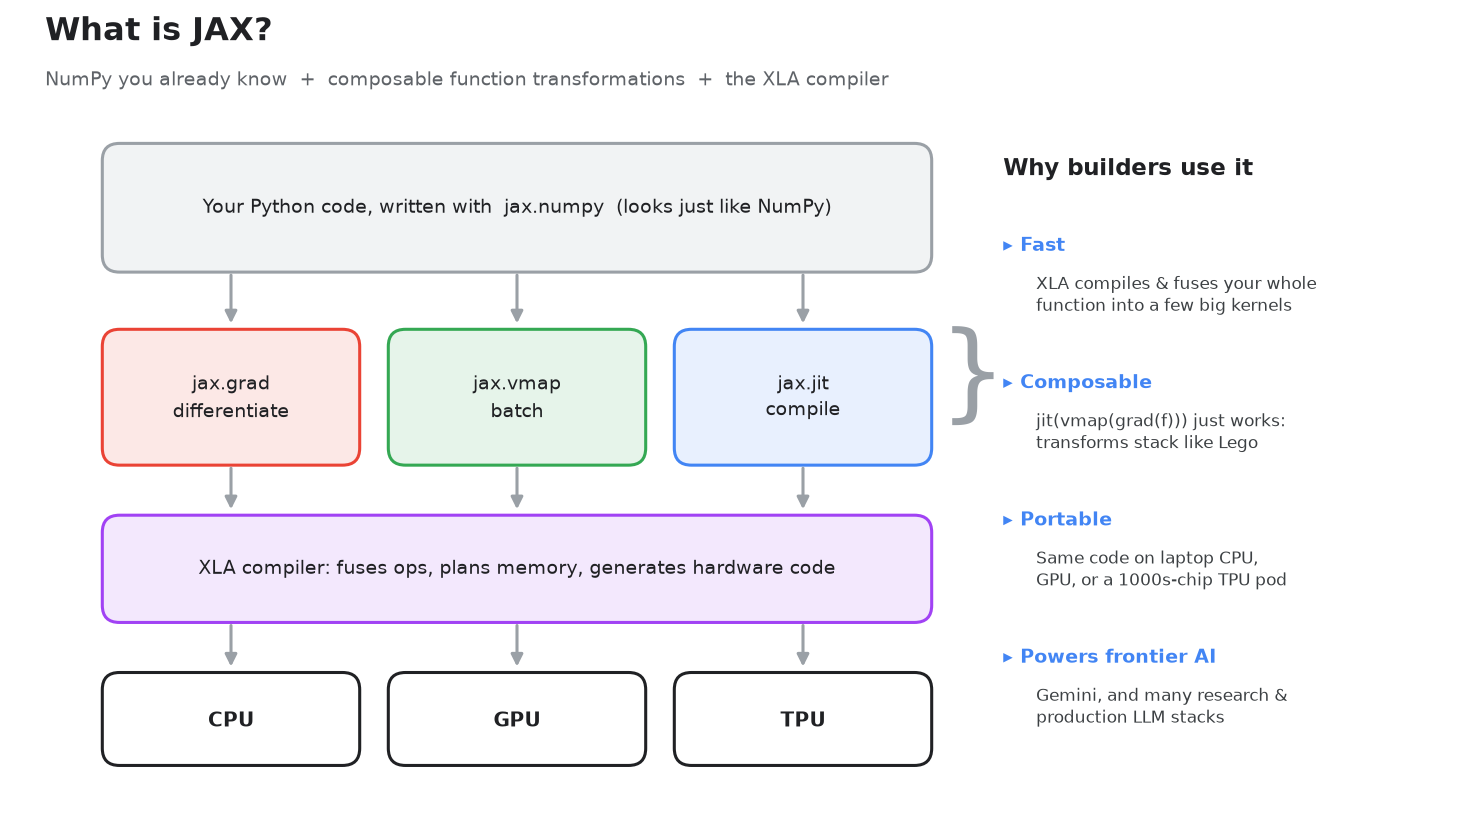

---
## Part 1: The JAX Trinity

JAX is built on **composable function transformations**:

| Transform | What it does |
|---|---|
| `jax.grad` | Automatic differentiation (gradients) |
| `jax.vmap` | Automatic vectorization (batching) |
| `jax.jit`  | Just-In-Time compilation via XLA |

Each one takes a function and returns a new function, so they stack like Lego bricks.

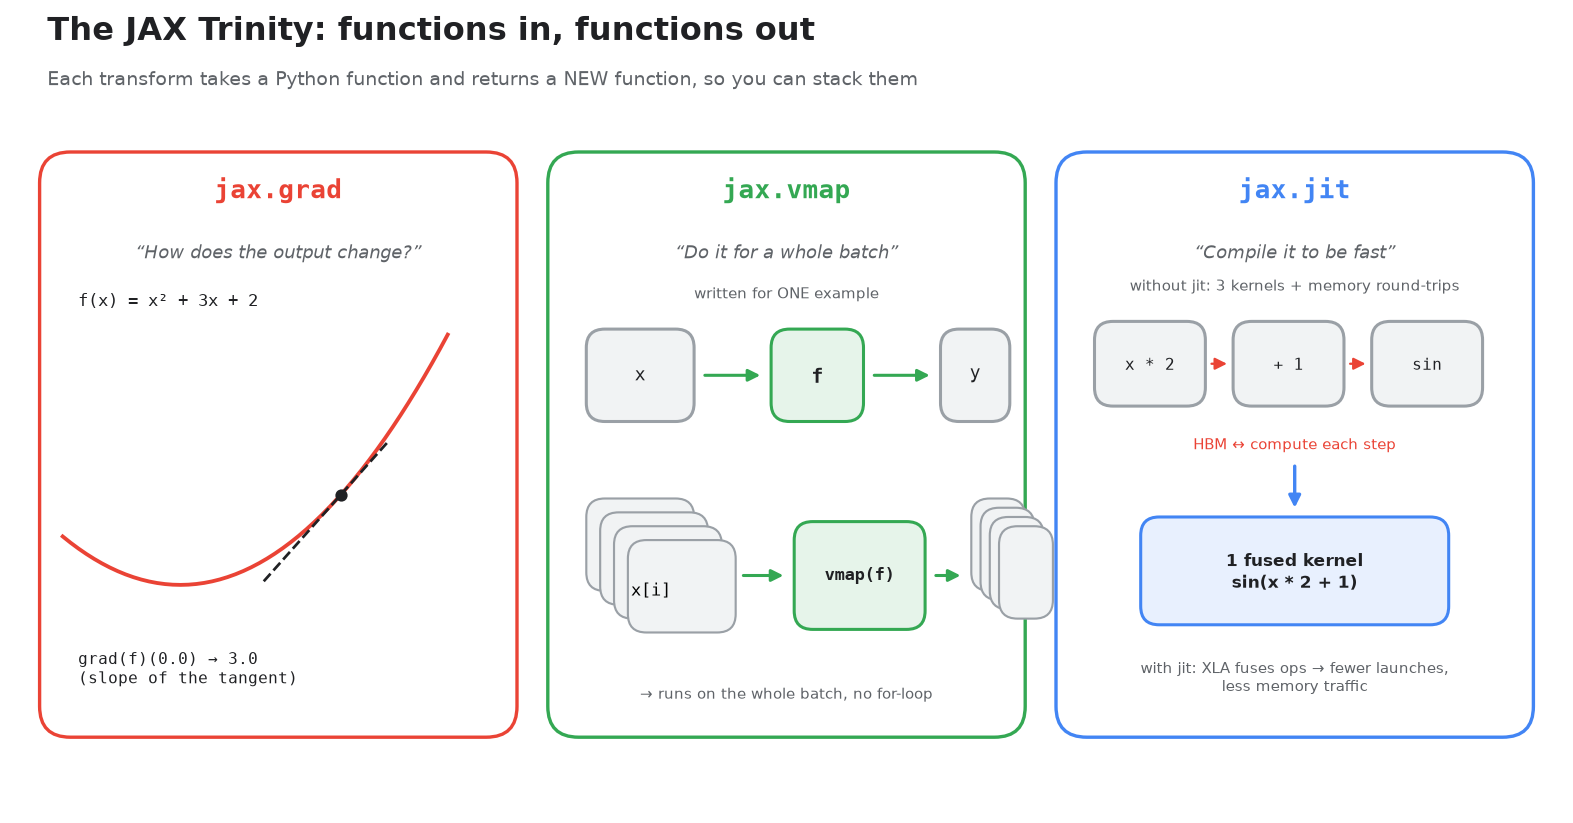

In [ ]:
# A simple scalar function
f = lambda x: x**2 + 3*x + 2

# 1. grad: df/dx = 2x + 3
df = jax.grad(f)
print(f"f(2.0)      = {f(2.0)}")
print(f"df/dx (2.0) = {df(2.0)}   (expected 7.0)")

# ❌ grad is defined for ONE scalar input -> scalar output. What about a batch?
x_batch = jnp.array([1.0, 2.0, 3.0])
try:
    df(x_batch)
except TypeError as e:
    print(f"\n❌ {type(e).__name__}: {str(e).splitlines()[0]}")

# ✅ 2. vmap: write it for one example, run it on a batch
df_batched = jax.vmap(df)
print(f"\n✅ vmap(grad(f))(batch) = {df_batched(x_batch)}   (expected [5. 7. 9.])")

# ✅ 3. jit: compile the whole composition with XLA
@jax.jit
def compiled_computation(x):
    return jax.vmap(jax.grad(jnp.sin))(x)

print(f"✅ jit(vmap(grad(sin)))(batch) = {compiled_computation(x_batch)}")

---
## Part 2: Tracing & Recompilation Storms

### ❌ The Trap: Side Effects & Python `print`
`jit` doesn't compile your Python source. It **runs your function once with abstract "tracer" values**, records the JAX operations, and compiles that graph. Python side effects (`print()`, appending to a list, mutating globals) only happen **during tracing**, not on later runs.

**Predict before running:** how many `[TRACE]` lines and how many `[RUNTIME]` lines will you see?

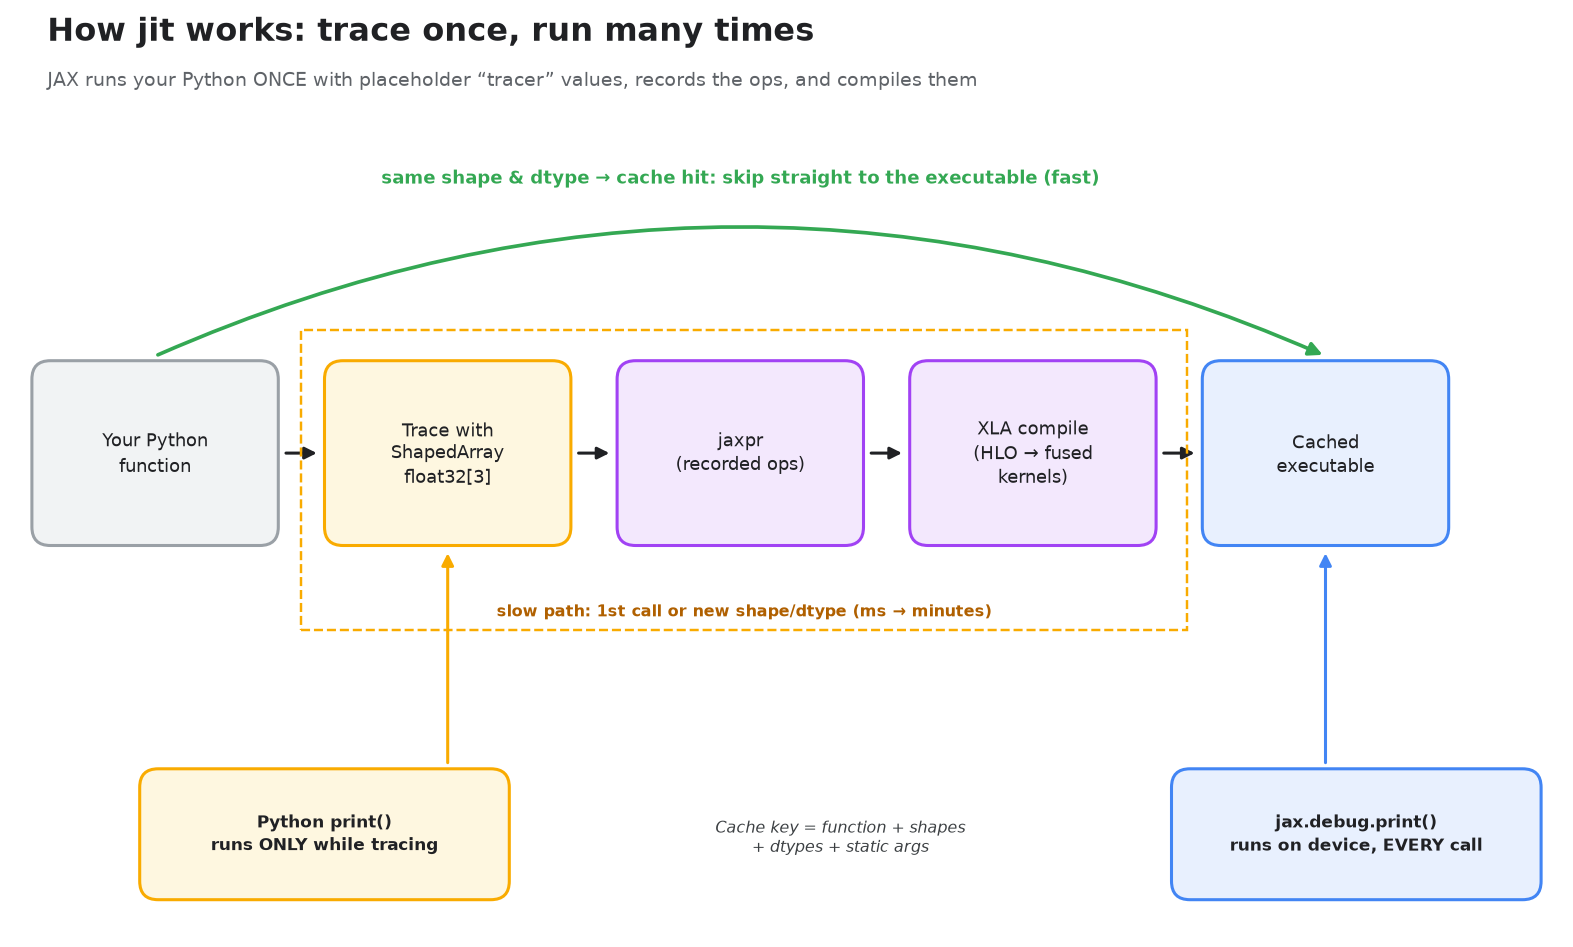

In [ ]:
@jax.jit
def tracing_demo(x):
    print("  [TRACE]   Python print() -> runs only while tracing")
    jax.debug.print("  [RUNTIME] jax.debug.print() -> runs on device, value = {}", x)
    return x * 2

print("--- Call 1: float scalar (trace + compile) ---")
tracing_demo(1.0)
jax.effects_barrier()   # wait for device-side prints so output lines up

print("--- Call 2: float scalar again (cache hit: Python never runs) ---")
tracing_demo(2.0)
jax.effects_barrier()

print("--- Call 3: new SHAPE (retrace + recompile) ---")
tracing_demo(jnp.array([1.0, 2.0]))
jax.effects_barrier()

✍️ **Your turn:** What happens if you call `tracing_demo(3)` (an **int**, not a float)? Predict, then run.

<details><summary>Hint</summary>The compile cache is keyed on <b>shape AND dtype</b> (and static arguments).</details>

In [ ]:
# ✍️ Your turn: predict first, then run
tracing_demo(3)
jax.effects_barrier()

### ❌ The Recompilation Storm (Dynamic Shapes)
Every new input **shape** triggers a new trace + XLA compile. In production this is very common: variable sequence lengths, a smaller last batch, dynamic batching in serving. The job "works" but spends its time compiling.

🔍 **Diagnose:** `jax_log_compiles` logs every compilation. It's the first flag to turn on when a JAX job is mysteriously slow.

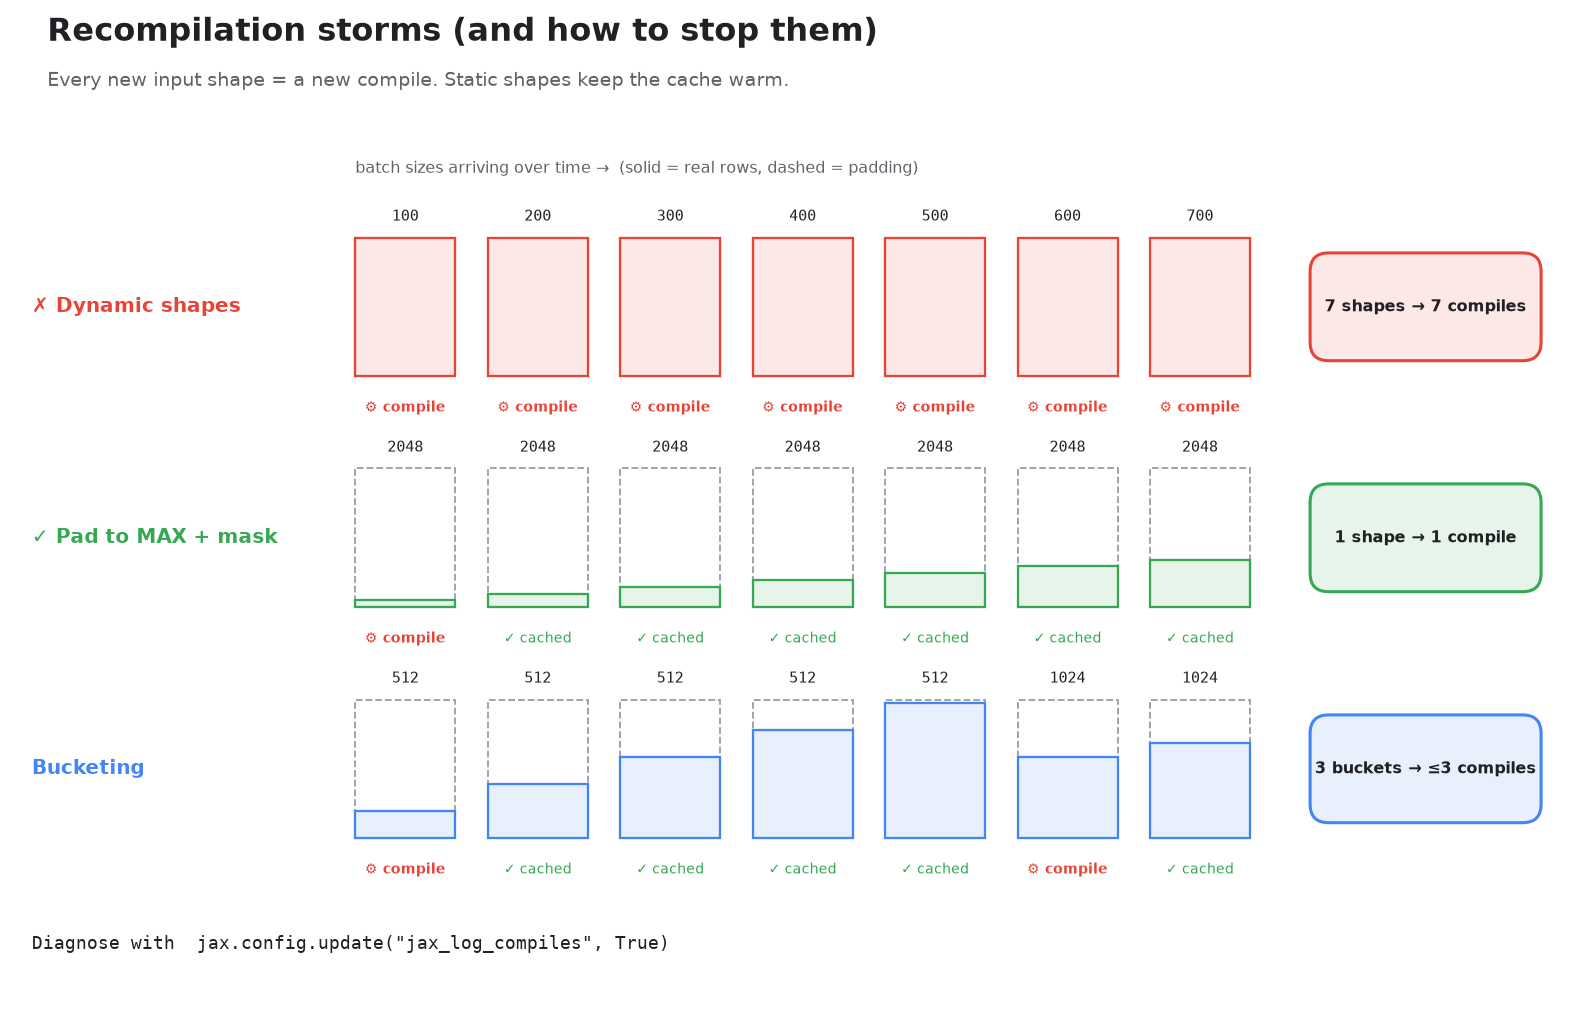

In [ ]:
@jax.jit
def process_batch(x):
    return jnp.sum(jnp.tanh(x @ x.T) * 2.0)

# 🔍 Turn on compile logging for 3 calls with 3 different shapes
jax.config.update("jax_log_compiles", True)
for n in (128, 256, 384):
    process_batch(np.ones((n, 512), np.float32)).block_until_ready()
jax.config.update("jax_log_compiles", False)
print("\n👆 One compile log per distinct shape.")

In [ ]:
# ❌ Broken: 20 different batch sizes -> 20 compiles
jax.clear_caches()
t0 = time.time()
for n in range(100, 2100, 100):
    process_batch(np.ones((n, 512), np.float32)).block_until_ready()
dynamic_total = time.time() - t0
print(f"❌ Dynamic shapes: {dynamic_total:.2f}s total for 20 steps")
if hasattr(process_batch, "_cache_size"):
    print(f"   Compiled versions in cache: {process_batch._cache_size()}")

### ✅ The Fix: Pad to a Static Shape + Mask
Pad every input to one fixed `MAX_BATCH` and pass the real length as a **runtime value**. The mask makes the padded rows contribute nothing.

> ⚠️ **Gotcha:** do the padding on the **host with NumPy**. If you pad with `jnp.zeros(...).at[:n].set(...)` outside `jit`, that padding op *itself* recompiles for every new shape, which moves the storm instead of fixing it.

In [ ]:
MAX_BATCH = 2048

@jax.jit
def process_batch_fixed(x, valid_rows):
    mask = (jnp.arange(MAX_BATCH) < valid_rows)[:, None]   # valid_rows is a runtime value, not a shape
    x = x * mask
    return jnp.sum(jnp.tanh(x @ x.T) * 2.0)

t0 = time.time()
for n in range(100, 2100, 100):
    padded = np.zeros((MAX_BATCH, 512), np.float32)   # pad on HOST
    padded[:n] = 1.0
    process_batch_fixed(padded, n).block_until_ready()
static_total = time.time() - t0
print(f"✅ Static (padded) shapes: {static_total:.2f}s total for 20 steps "
      f"(vs {dynamic_total:.2f}s dynamic)")
if hasattr(process_batch_fixed, "_cache_size"):
    print(f"   Compiled versions in cache: {process_batch_fixed._cache_size()}")

✍️ **Your turn: Bucketing.** Padding everything to 2048 wastes compute on small batches. Production systems pad to the **nearest bucket** instead (e.g. 512 / 1024 / 2048): a few compiles, much less waste.

Write `bucketed_process(batch)` that pads `batch` up to the smallest bucket that fits and calls a jitted function. How many compiles do you get for the 20 sizes above?

In [ ]:
# ✍️ Your turn
BUCKETS = (512, 1024, 2048)

def bucketed_process(batch):
    ...  # pick the bucket, pad on host, call a jitted function

In [ ]:
#@title 🔑 Solution (double-click to reveal)
BUCKETS = (512, 1024, 2048)

@jax.jit
def process_bucket(x, valid_rows):
    mask = (jnp.arange(x.shape[0]) < valid_rows)[:, None]   # x.shape is static per bucket
    x = x * mask
    return jnp.sum(jnp.tanh(x @ x.T) * 2.0)

def bucketed_process(batch):
    n = batch.shape[0]
    size = next(b for b in BUCKETS if b >= n)
    padded = np.zeros((size, batch.shape[1]), batch.dtype)
    padded[:n] = batch
    return process_bucket(padded, n)

t0 = time.time()
for n in range(100, 2100, 100):
    bucketed_process(np.ones((n, 512), np.float32)).block_until_ready()
print(f"🪣 Bucketed: {time.time() - t0:.2f}s total")
if hasattr(process_bucket, "_cache_size"):
    print(f"   Compiled versions in cache: {process_bucket._cache_size()} (one per bucket)")

---
## Part 3: Shape & Batch-Size Mismatches in `vmap`

`vmap` needs to know **which axis is the batch axis** for every input, and all batch axes must have the **same size**. JAX's error messages tell you exactly which argument and axis disagree, so read them carefully.

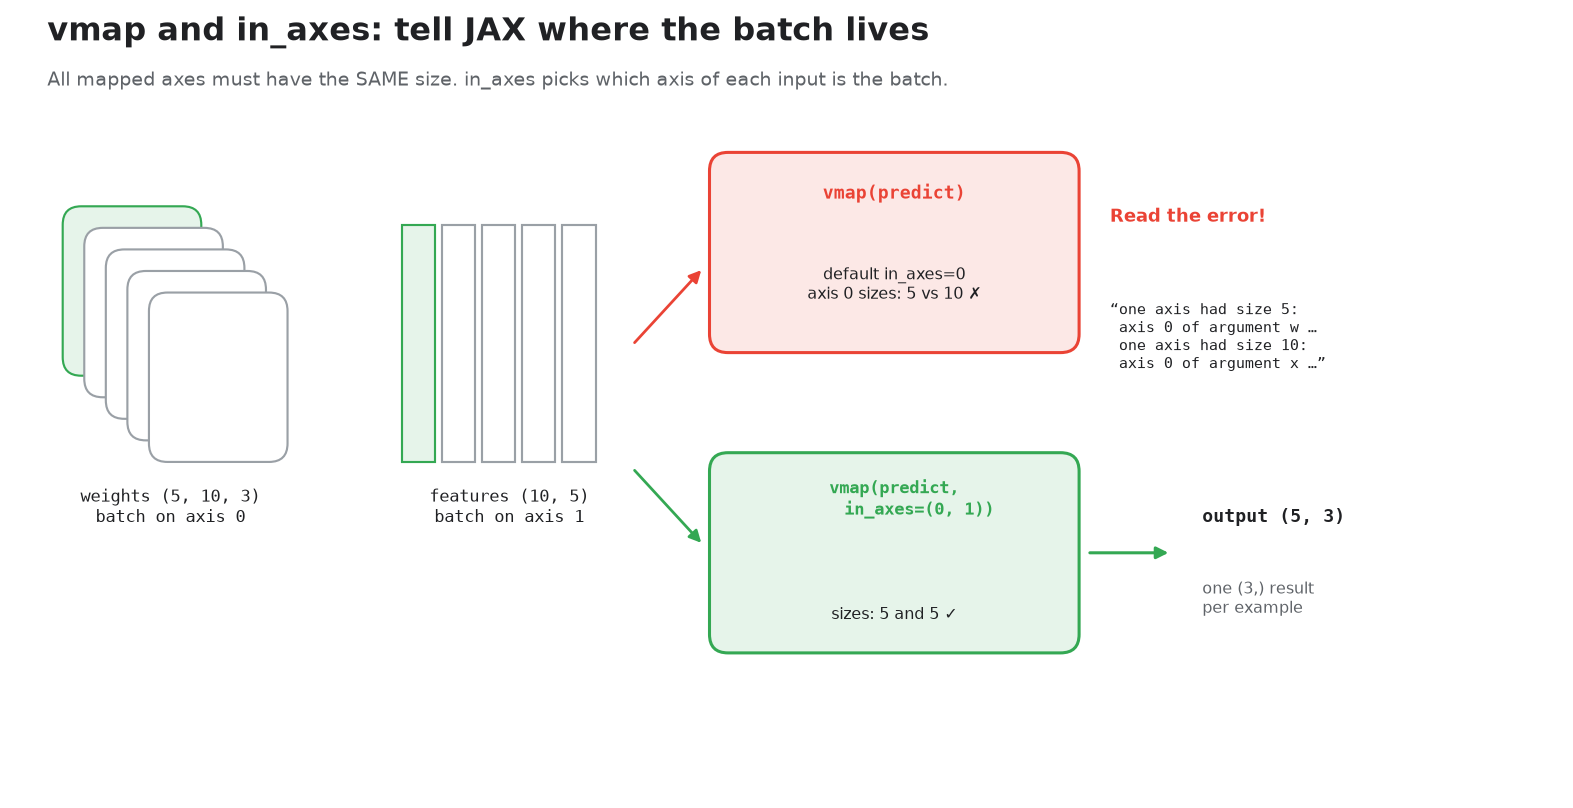

In [ ]:
weights  = jnp.ones((5, 10, 3))   # batch of 5 matrices, each (10, 3)
features = jnp.ones((10, 5))      # batch of 5 vectors... but the batch is on axis 1!

def predict(w, x):
    # w: (10, 3), x: (10,)  ->  (3,)
    return jnp.dot(x, w)

# ❌ Broken: vmap assumes batch axis 0 for every input
try:
    jax.vmap(predict)(weights, features)
except ValueError as e:
    print("❌ JAX shape mismatch:\n")
    print(e)

### ✅ The Fix: `in_axes`
Tell `vmap` that `weights` is batched on axis 0 and `features` on axis 1.

In [ ]:
batched_predict = jax.vmap(predict, in_axes=(0, 1))
output = batched_predict(weights, features)
print(f"✅ Output shape: {output.shape}   (expected (5, 3))")

✍️ **Your turn: the incorrect batch size.** Below, the data loader produced 5 feature vectors but there are only 4 weight matrices. **Predict the error message** (which argument? which sizes?) before running.

In [ ]:
weights_4  = jnp.ones((4, 10, 3))
features_5 = jnp.ones((5, 10))     # batch on axis 0 this time

try:
    jax.vmap(predict)(weights_4, features_5)
except ValueError as e:
    print("❌", e)

### 🔍 Production Tool: `jax.eval_shape`
On a real model you don't want to allocate gigabytes just to find a shape bug. `jax.eval_shape` traces the function with **abstract shapes only**: no FLOPs and no device memory are used. You can check the shapes of a model that wouldn't even fit on your laptop.

In [ ]:
# A batch of 4096 x (2048 -> 8192) layers: ~275 GB of weights if we actually allocated it!
big_w = jax.ShapeDtypeStruct((4096, 2048, 8192), jnp.float32)
big_x = jax.ShapeDtypeStruct((2048, 4096), jnp.float32)   # batch on axis 1

out = jax.eval_shape(jax.vmap(predict, in_axes=(0, 1)), big_w, big_x)
print(f"✅ Output would be {out.shape} {out.dtype}, checked without allocating anything")

---
## Part 4: Memory: Rematerialization & Remat Policies

For the backward pass, JAX keeps the forward pass's intermediate values (**residuals**/activations). For deep models these residuals, not the weights, are often what blows past accelerator memory (HBM) and causes `RESOURCE_EXHAUSTED` (OOM).

**Rematerialization** (`jax.checkpoint`, a.k.a. `jax.remat`) trades **compute for memory**: drop residuals in the forward pass and recompute them during the backward pass. **Remat policies** let you choose *which* residuals to keep.

We'll measure memory directly using XLA's own compile-time memory analysis, the same check you can run before launching a large job.

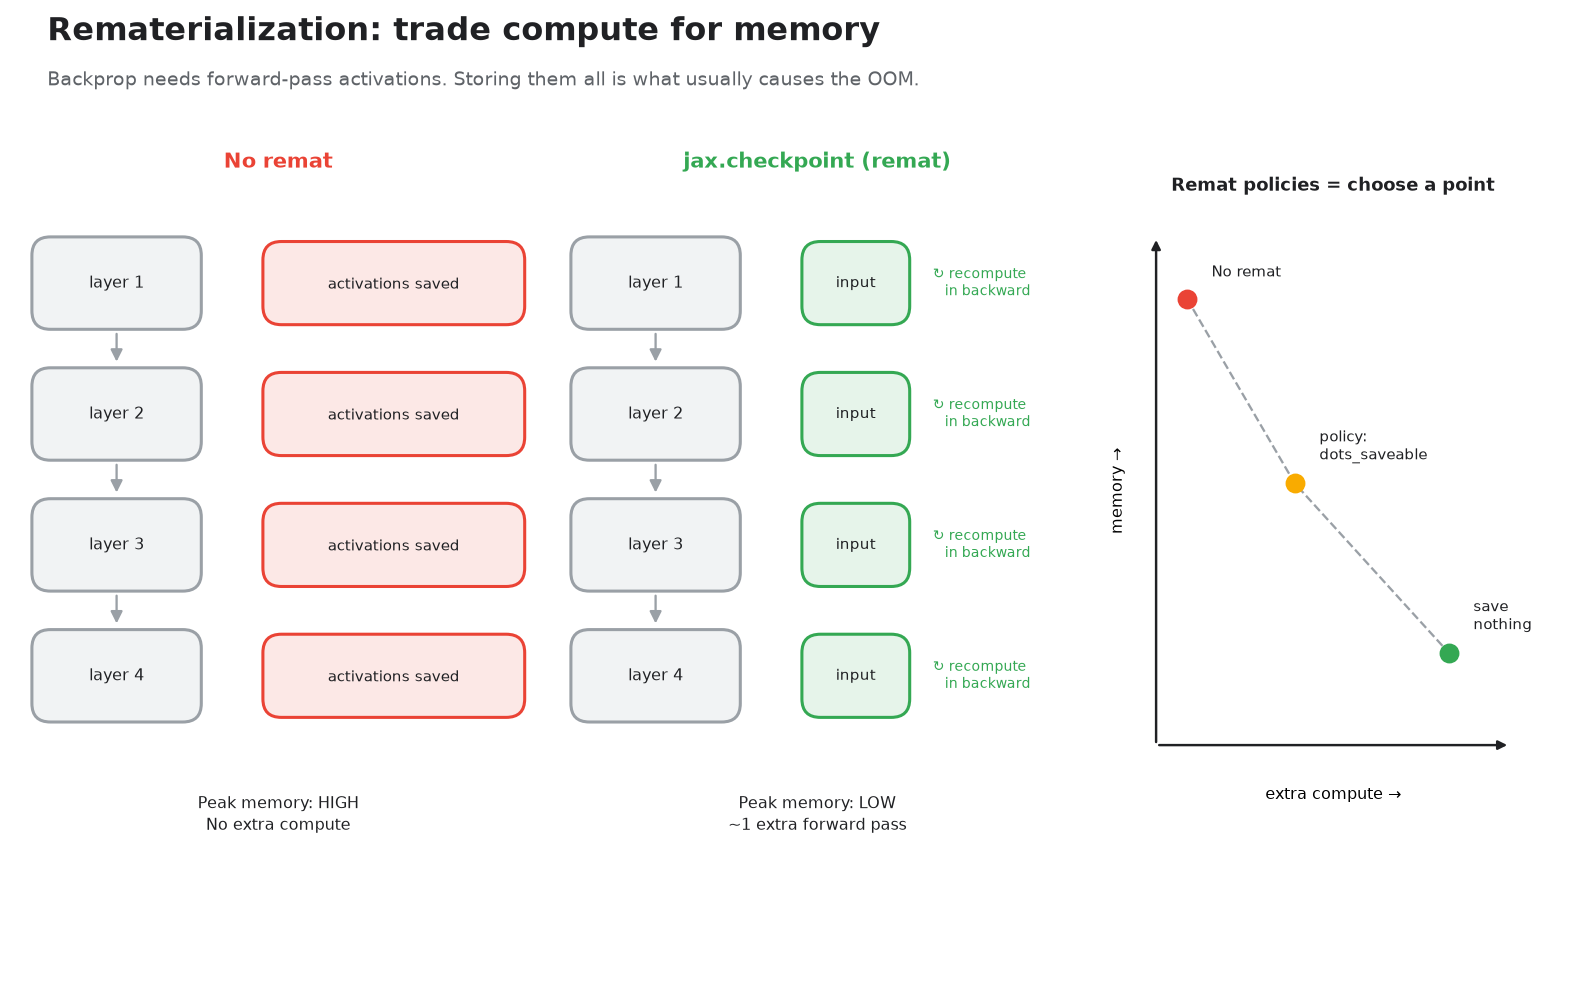

In [ ]:
# Problem size: shrinks automatically on CPU so everyone can follow along
if jax.default_backend() == "cpu":
    NUM_LAYERS, DIM, BATCH = 12, 256, 256
else:
    NUM_LAYERS, DIM, BATCH = 32, 1024, 2048     # sized for a 16 GB TPU v5e / T4
HIDDEN = 4 * DIM
print(f"Model: {NUM_LAYERS} transformer-style MLP blocks ({DIM} -> {HIDDEN} -> {DIM}), batch {BATCH}")

def mlp_layer(params, x):
    # The feed-forward block found in every transformer layer
    w1, b1, w2, b2 = params
    h = jax.nn.gelu(jnp.dot(x, w1) + b1)   # expand 4x: big (BATCH, HIDDEN) activations
    return x + jnp.dot(h, w2) + b2         # project back + residual connection

def init_layer(key):
    k1, k2 = jax.random.split(key)
    return (jax.random.normal(k1, (DIM, HIDDEN)) * 0.02, jnp.zeros((HIDDEN,)),
            jax.random.normal(k2, (HIDDEN, DIM)) * 0.02, jnp.zeros((DIM,)))

key = jax.random.PRNGKey(0)
# vmap again! Initialise all layers at once -> stacked params with a leading layer axis
stacked = jax.vmap(init_layer)(jax.random.split(key, NUM_LAYERS))
x = jax.random.normal(key, (BATCH, DIM))
print("Stacked param shapes:", jax.tree.map(lambda a: a.shape, stacked))

### ❌ Compile-Time Trap: Python Loops Unroll
A Python `for` loop inside `jit` is **unrolled**: N layers become N copies of the layer in the XLA graph, so compile time grows with depth. `jax.lax.scan` compiles the layer **once** and loops over it.

In [ ]:
def loss_unrolled(stacked, x):
    act = x
    for i in range(NUM_LAYERS):               # ❌ unrolled NUM_LAYERS times
        act = mlp_layer(jax.tree.map(lambda a: a[i], stacked), act)
    return jnp.sum(act)

def loss_scan(stacked, x, layer_fn=mlp_layer):
    def body(act, p):
        return layer_fn(p, act), None
    act, _ = jax.lax.scan(body, x, stacked)   # ✅ compiled once, looped NUM_LAYERS times
    return jnp.sum(act)

# Compile only (no execution) using abstract shapes
spec = lambda a: jax.ShapeDtypeStruct(a.shape, a.dtype)
args = (jax.tree.map(spec, stacked), spec(x))

for name, fn in [("❌ Python loop", loss_unrolled), ("✅ lax.scan", loss_scan)]:
    t0 = time.time()
    jax.jit(jax.grad(fn)).lower(*args).compile()
    print(f"{name:15s} compile time: {time.time() - t0:5.2f}s")

### 🔍 What does the backward pass actually save?
`print_saved_residuals` lists every array JAX keeps for the backward pass. Compare one layer **without** remat, **with** remat, and with the `dots_saveable` **policy**.

In [ ]:
from jax.ad_checkpoint import print_saved_residuals

one_layer = jax.tree.map(lambda a: a[0], stacked)
variants = {
    "No remat":                    mlp_layer,
    "remat (save nothing)":        jax.checkpoint(mlp_layer),
    "remat policy: dots_saveable": jax.checkpoint(
        mlp_layer, policy=jax.checkpoint_policies.dots_saveable),
}

for name, layer_fn in variants.items():
    print(f"=== {name} ===")
    print_saved_residuals(lambda p, a: jnp.sum(layer_fn(p, a)), one_layer, x)
    print()

### 🔍 Measure peak memory for the full model
`jit(...).lower(...).compile().memory_analysis()` reports how much **temporary** memory (mostly residuals) XLA plans to use, **before running anything**.

In [ ]:
def memory_report(layer_fn):
    loss = functools.partial(loss_scan, layer_fn=layer_fn)
    compiled = jax.jit(jax.grad(loss)).lower(stacked, x).compile()
    return compiled, compiled.memory_analysis()

compiled_fns = {}
for name, layer_fn in variants.items():
    compiled, mem = memory_report(layer_fn)
    compiled_fns[name] = compiled
    if mem is None:
        print(f"{name:30s} (memory analysis not available on this backend)")
        continue
    print(f"{name:30s} temp: {mem.temp_size_in_bytes/1e9:6.2f} GB | "
          f"args: {mem.argument_size_in_bytes/1e9:5.2f} GB | "
          f"outputs: {mem.output_size_in_bytes/1e9:5.2f} GB")

### ⏱️ The trade-off: remat costs compute
Memory goes down, step time goes up (the forward pass is partly re-run). Picking a remat policy means choosing a point on this curve.

In [ ]:
def time_step(compiled, n=5):
    jax.block_until_ready(compiled(stacked, x))          # warm-up
    t0 = time.time()
    for _ in range(n):
        out = compiled(stacked, x)
    jax.block_until_ready(out)
    return (time.time() - t0) / n * 1000

for name, compiled in compiled_fns.items():
    print(f"{name:30s} step time: {time_step(compiled):8.1f} ms")

### 🔍 Will it fit? (Catch the OOM before it happens)
On a production pod you can't afford to find out about an OOM an hour into a job. Compare XLA's planned memory against the device's HBM limit.

✍️ **Your turn:** increase `BATCH_TEST` until "No remat" no longer fits but "remat" does.

In [ ]:
BATCH_TEST = BATCH * 2   # ✍️ try * 4 or * 8

stats = jax.devices()[0].memory_stats()
limit = stats.get("bytes_limit") if stats else None
x_spec = jax.ShapeDtypeStruct((BATCH_TEST, DIM), jnp.float32)
p_spec = jax.tree.map(spec, stacked)

for name, layer_fn in variants.items():
    loss = functools.partial(loss_scan, layer_fn=layer_fn)
    mem = jax.jit(jax.grad(loss)).lower(p_spec, x_spec).compile().memory_analysis()
    if mem is None:
        print("Memory analysis not available on this backend.")
        break
    total = mem.temp_size_in_bytes + mem.argument_size_in_bytes + mem.output_size_in_bytes
    verdict = "" if limit is None else ("✅ fits" if total < limit else "❌ would OOM")
    print(f"{name:30s} needs {total/1e9:6.2f} GB {verdict}")

if limit:
    print(f"\nDevice HBM limit: {limit/1e9:.2f} GB")
else:
    print("\n(No device memory limit reported on this backend: try a TPU/GPU runtime)")

---
## Part 5: Profiling with Perfetto

The pipeline below *works*, but it's slow. Is it the model, or something else? Instead of guessing, we'll **capture a trace** and look at the timeline.

* `jax.profiler.trace(..., create_perfetto_trace=True)` writes a `perfetto_trace.json.gz` you can open in **https://ui.perfetto.dev**
* `jax.profiler.StepTraceAnnotation` labels each training step in the timeline

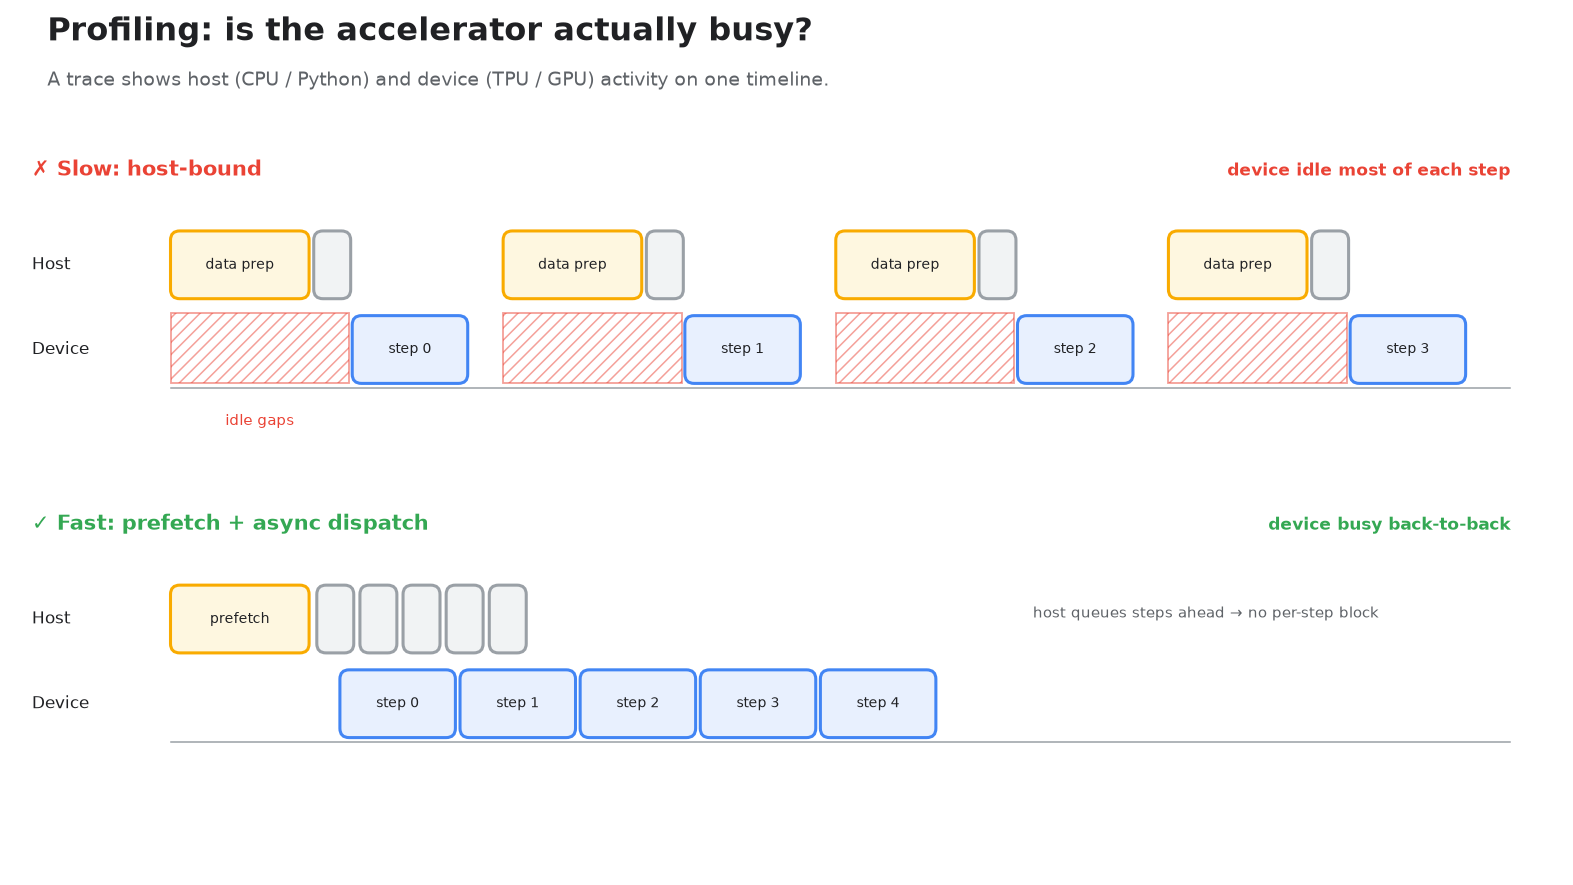

In [ ]:
train_step = compiled_fns["No remat"]

def make_batch_on_host(step):
    # Simulates a slow data loader: generate + preprocess on the CPU every step
    rng = np.random.default_rng(step)
    batch = rng.standard_normal((BATCH, DIM), dtype=np.float32)
    return np.sort(batch, axis=1)   # pretend preprocessing

def find_perfetto_trace(log_dir):
    found = sorted(glob.glob(f"{log_dir}/**/perfetto_trace.json.gz", recursive=True),
                   key=os.path.getmtime)
    return found[-1] if found else None

# ❌ Slow pipeline: host data prep sits on the critical path, then we block every step
SLOW_DIR = "/tmp/jax_profile/slow"
with jax.profiler.trace(SLOW_DIR, create_perfetto_trace=True):
    t0 = time.time()
    for step in range(5):
        with jax.profiler.StepTraceAnnotation("train", step_num=step):
            batch = make_batch_on_host(step)          # CPU work, accelerator idle
            grads = train_step(stacked, batch)        # implicit host -> device copy
            jax.block_until_ready(grads)              # sync every step
    slow_time = time.time() - t0
print(f"❌ Slow pipeline: {slow_time:.2f}s for 5 steps")
print(f"   Trace: {find_perfetto_trace(SLOW_DIR)}")

### ✅ The Fix: get data prep off the critical path
Prepare batches ahead of time (in production: a background data loader / prefetch), copy them to the device with `jax.device_put`, and **don't block every step**: JAX dispatches work asynchronously, so the host can queue the next step while the accelerator computes.

In [ ]:
FAST_DIR = "/tmp/jax_profile/fast"
batches = [jax.device_put(make_batch_on_host(s)) for s in range(5)]   # "prefetched"
jax.block_until_ready(batches)

with jax.profiler.trace(FAST_DIR, create_perfetto_trace=True):
    t0 = time.time()
    for step, batch in enumerate(batches):
        with jax.profiler.StepTraceAnnotation("train", step_num=step):
            grads = train_step(stacked, batch)        # async dispatch, no per-step block
    jax.block_until_ready(grads)
    fast_time = time.time() - t0
print(f"✅ Fast pipeline: {fast_time:.2f}s for 5 steps (vs {slow_time:.2f}s)")
print(f"   Trace: {find_perfetto_trace(FAST_DIR)}")
if jax.default_backend() == "cpu":
    print("   (On a CPU runtime the host IS the device, so the gap is small: try TPU/GPU.)")

### 🔍 Open the traces in Perfetto
1. Run the cell below to download both traces.
2. Go to **https://ui.perfetto.dev** → *Open trace file* → pick a `.json.gz`.
3. Compare the **host (Python) threads** with the **device (TPU/GPU) track**. In the slow trace, look for gaps on the device track: those are times the accelerator sat idle waiting for the host.

In [ ]:
slow_trace, fast_trace = find_perfetto_trace(SLOW_DIR), find_perfetto_trace(FAST_DIR)
try:
    from google.colab import files
    for path, name in [(slow_trace, "slow"), (fast_trace, "fast")]:
        if path:
            dst = f"/tmp/perfetto_{name}.json.gz"
            os.system(f"cp '{path}' '{dst}'")
            files.download(dst)
    print("⬇️ Downloads started: open them at https://ui.perfetto.dev")
except ImportError:
    print("Not running in Colab. Trace files are at:")
    print(" ", slow_trace)
    print(" ", fast_trace)

### (Optional) Deeper analysis with XProf in TensorBoard
The same trace directories also contain `.xplane.pb` files for **XProf** (TensorBoard's profiler plugin), which adds op-level stats, roofline analysis and memory views. Installing it takes a minute, so it's optional during the workshop.

In [ ]:
%pip install -q tensorboard tensorboard-plugin-profile
%load_ext tensorboard
%tensorboard --logdir=/tmp/jax_profile

---
## 🧭 Wrap-up: From Colab to Production

| What you saw today | Production version | Tool |
|---|---|---|
| `print` ran once | Hidden state bugs, stale configs in `jit` | `jax.debug.print`, `jax.effects_barrier` |
| Recompilation storm | Variable sequence lengths, ragged last batch | `jax_log_compiles`, padding / bucketing |
| `vmap` axis mismatch | Data loader / sharding batch-size bugs | Read the error; `jax.eval_shape` |
| Long compile from loops | 10+ minute compiles on huge models | `lax.scan` over layers |
| Residual memory | `RESOURCE_EXHAUSTED` on a pod | `memory_analysis()`, `jax.checkpoint` + policies |
| Host-bound steps | Low accelerator utilization ("goodput") | `jax.profiler` + Perfetto / XProf |

**Keep going:** [JAX docs](https://docs.jax.dev) · [Sharp bits](https://docs.jax.dev/en/latest/notebooks/Common_Gotchas_in_JAX.html) · [Gradient checkpointing](https://docs.jax.dev/en/latest/gradient-checkpointing.html) · [Profiling](https://docs.jax.dev/en/latest/profiling.html) · [Flax](https://flax.readthedocs.io)